# SVM

SVM helps us to find the best decision boundary that will help us seperate our space into classes. 

![](svm1.png)


The decision boundary is searched using the maximum margin line.

![](svm2.png)

The decision boundary line is drawn equidistant from the red and green points and the margin i.e, the distance between the decision boundary and the points known as __margin__ must be maximised. The red and green points are known as __Support Vectors__ as the other red and green points do not contribute to the margin.

The decision boundary is also known as __maximum margin hyperplane__. (hyperplane - as its multidimensional)

The green dotted line is known as __Positive hyperplane__ and the red dotted line is known as __Negative hypeplane__. The names are given based on the position of these lines (as per convention), the line to the right of __maximum margin hyperplane__ is known as __Positive hyperplane__ and to the left is known as __Negative hypeplane__.

The essence of SVM is we are working with linearly seperable dataset where we can create a hyperplane to seperate two categories.

## What is so special about SVMs?


![](svm3.png)


Here we look at the points which are very much similar to the other class i.e, closer to the other class. These are support vectors and will be very close to the decision boundary. 

So it is a bit extreme type of algorithm as it works/targets the points at the extreme ends or boundary. This is what makes the SVM different to most of the other classification algorithms. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv("..\Social_Network_Ads.csv")
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\S'
<>:1: SyntaxWarning: invalid escape sequence '\S'
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_25352\746172019.py:1: SyntaxWarning: invalid escape sequence '\S'
  df = pd.read_csv("..\Social_Network_Ads.csv")


,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [3]:
X = df.iloc[:,:-1]
X.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [4]:
y = df.iloc[:,-1]
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

## Splitting the dataset into the Training set and Test set

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)
X_train.head()

,Age,EstimatedSalary
250,44,39000
63,32,120000
312,38,50000
159,32,135000
283,52,21000


## Feature Scaling

In [6]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## [Support Vector Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

In [7]:
from sklearn.svm import SVC
clf = SVC(kernel = 'linear', random_state = 0)

In [8]:
clf.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


#### Predicting a new result

In [9]:
y_pred = clf.predict(X_test)

#### making the confusion matrix

In [10]:
from sklearn.metrics import confusion_matrix, accuracy_score

In [11]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix: ")
cm

Confusion matrix: 


array([[66,  2],
       [ 8, 24]])

In [12]:
accuracy_score(y_test, y_pred)

0.9

##### Visualizing the test set result

c:\Work\Github\Machine-Learning-A-Z-Udemy\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_25352\278693373.py:25: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('red', 'green'))(i), label = j)


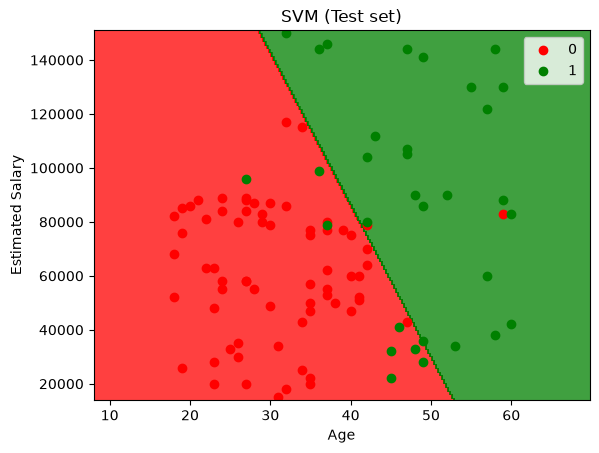

In [15]:
from matplotlib.colors import ListedColormap

# Invert scaling so the axes are plotted in original Age / EstimatedSalary
# units rather than the standardized values the model was actually trained on
X_set, y_set = sc.inverse_transform(X_test), y_test

# Build a fine grid covering the feature space. step=0.25 makes the grid much
# denser than KNN's step=1 example -> needed here because SVM's linear
# boundary is a straight line, and a coarse grid can make it look jagged
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 0.25))

# Classify every point on the grid (re-scaling it first, since clf was
# fitted on scaled data) -> reshape back to grid shape to get the decision
# region at every (Age, EstimatedSalary) coordinate
plt.contourf(X1, X2, clf.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

# Overlay the actual test points, coloured by their true class, so we can
# see which points fall on the wrong side of the (linear) decision boundary
# -> those are the misclassifications reflected in the confusion matrix above
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()



## Pros and Cons of Support Vector Machines

### **Pros (Strengths)**

* **High-Dimensional Efficiency:** Works exceptionally well when the feature dimension $p$ is larger than the number of samples $n$.
* **Memory Optimization:** Uses only a subset of training points (**support vectors**) to build the decision boundary rather than storing all data points in memory. (Compare it to KNN which is highly memory-inefficient).
* **Versatility:** Accommodates linear, non-linear, and domain-customized decision boundaries via interchangeable kernel functions.
* **Overfitting Resistance:** Margin maximization minimizes structural risk, helping prevent overfitting in high-dimensional domains.

### **Cons (Limitations)**

* **Scaling Bottlenecks:** Training computational complexity scales between $O(N^2)$ and $O(N^3)$. It becomes slow on large datasets ($>100,000$ samples).
* **Sensitivity to Noise:** Overlapping classes and noisy data points directly degrade margin boundaries.
* **Feature Scaling Dependency:** Requires strict input standardization (e.g., Z-score scaling); unscaled features ruin distance metrics.
* **Lack of Direct Probabilities:** Output decisions are non-probabilistic distances to the hyperplane; obtaining probabilities requires compute-heavy cross-validation (Platt scaling).